# SkinCon Knowledge Graph Construction

Builds a heterogeneous dermatology KG from SkinCon concept annotations and Fitzpatrick17k labels. Images are not required.

**Node types**: disease (113), concept (48), category (9-partition), super-category (3-partition)

**Edge types**
- `has_concept` (disease to concept): data-driven, weighted by smoothed P(concept | disease)
- `co_occurs` (concept to concept): positive PMI over images
- `is_a` (disease to category to super-category): hierarchy
- `has_concept_kb` (optional): knowledge-driven edges from an LLM, for later fusion

In [ ]:
# %pip install pandas numpy networkx matplotlib -i https://pypi.tuna.tsinghua.edu.cn/simple

## 1. Config

In [2]:
SKINCON_CSV = "image.csv"
F17K_CSV = "fitzpatrick17k.csv"
OUT_DIR = "data/skincon_kg"

SMOOTH_ALPHA = 5.0     # Bayesian smoothing strength toward the global concept prior
EDGE_MIN_PROB = 0.20   # min smoothed P(concept | disease) to create a has_concept edge
EDGE_MIN_COUNT = 2     # min number of images supporting the edge
EDGE_MIN_LIFT = 1.0    # keep only concepts at least as frequent as their global rate
DISTINCT_MIN_LIFT = 3.0   # also keep rare but strongly enriched concepts (e.g. Telangiectasia in BCC)
DISTINCT_MIN_COUNT = 3
PMI_MIN = 0.5          # min PMI for concept co-occurrence edges
COOC_MIN_COUNT = 10    # min co-occurrence count for concept edges

## 2. Load data

In [4]:
import os, json
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

os.makedirs(OUT_DIR, exist_ok=True)

sk = pd.read_csv(SKINCON_CSV).drop(columns=["Unnamed: 0"], errors="ignore")
sk = sk[sk["Do not consider this image"] == 0].drop(columns=["Do not consider this image"])
sk["md5"] = sk["ImageID"].str.replace(".jpg", "", regex=False)
CONCEPTS = [c for c in sk.columns if c not in ("ImageID", "md5")]

f17k = pd.read_csv(F17K_CSV)
df = sk.merge(f17k, left_on="md5", right_on="md5hash", how="inner")
DISEASES = sorted(df["label"].unique())
print(f"images {len(df)} | diseases {len(DISEASES)} | concepts {len(CONCEPTS)}")

images 3230 | diseases 113 | concepts 48


## 3. Disease to concept statistics

Raw P(c|d) is unreliable for tiny classes, so it is shrunk toward the global prior P(c):

$\hat P(c\mid d) = \dfrac{n_{dc} + \alpha P(c)}{n_d + \alpha}$, and lift $= \hat P(c\mid d) / P(c)$.

In [5]:
X = df[CONCEPTS].astype(int)
n_d = df.groupby("label").size().reindex(DISEASES)                  # images per disease
n_dc = X.groupby(df["label"]).sum().reindex(DISEASES)              # concept counts per disease
p_c = X.mean()                                                     # global concept prior

p_raw = n_dc.div(n_d, axis=0)
p_smooth = (n_dc + SMOOTH_ALPHA * p_c).div(n_d + SMOOTH_ALPHA, axis=0)
lift = p_smooth.div(p_c.replace(0, np.nan), axis=1).fillna(0)

p_smooth.round(4).to_csv(os.path.join(OUT_DIR, "disease_concept_prob.csv"))
print("Global concept prior (top 10):")
print(p_c.sort_values(ascending=False).head(10).round(3).to_string())

Global concept prior (top 10):
Erythema                    0.662
Plaque                      0.609
Papule                      0.362
Brown(Hyperpigmentation)    0.235
Scale                       0.212
Crust                       0.154
White(Hypopigmentation)     0.080
Yellow                      0.076
Erosion                     0.062
Nodule                      0.059


## 4. Build the graph

In [6]:
G = nx.MultiDiGraph()

# nodes
for d in DISEASES:
    row = df[df["label"] == d].iloc[0]
    G.add_node(f"D:{d}", ntype="disease", name=d, n_images=int(n_d[d]),
               category=row["nine_partition_label"], super_category=row["three_partition_label"])
for c in CONCEPTS:
    G.add_node(f"C:{c}", ntype="concept", name=c, prior=float(p_c[c]), n_images=int(X[c].sum()))
for cat in sorted(df["nine_partition_label"].unique()):
    G.add_node(f"G:{cat}", ntype="category", name=cat)
for sup in sorted(df["three_partition_label"].unique()):
    G.add_node(f"S:{sup}", ntype="super_category", name=sup)

# disease -has_concept-> concept (data-driven)
for d in DISEASES:
    for c in CONCEPTS:
        p, cnt, lf = p_smooth.at[d, c], n_dc.at[d, c], lift.at[d, c]
        common = p >= EDGE_MIN_PROB and lf >= EDGE_MIN_LIFT          # frequent in this disease
        distinctive = lf >= DISTINCT_MIN_LIFT and cnt >= DISTINCT_MIN_COUNT  # rare overall, enriched here
        if cnt >= EDGE_MIN_COUNT and (common or distinctive):
            G.add_edge(f"D:{d}", f"C:{c}", etype="has_concept", weight=float(p),
                       lift=float(lf), count=int(cnt), source="data")

# hierarchy
hier = df[["label", "nine_partition_label", "three_partition_label"]].drop_duplicates()
for _, r in hier.iterrows():
    G.add_edge(f"D:{r.label}", f"G:{r.nine_partition_label}", etype="is_a", weight=1.0, source="f17k")
for _, r in hier[["nine_partition_label", "three_partition_label"]].drop_duplicates().iterrows():
    G.add_edge(f"G:{r.nine_partition_label}", f"S:{r.three_partition_label}", etype="is_a", weight=1.0, source="f17k")

# concept -co_occurs- concept (PMI over images)
Xa = X.values.astype(float)
N = len(Xa)
co = Xa.T @ Xa
pc = co.diagonal() / N
for i, ci in enumerate(CONCEPTS):
    for j in range(i + 1, len(CONCEPTS)):
        cnt = co[i, j]
        if cnt < COOC_MIN_COUNT:
            continue
        pmi = np.log((cnt / N) / (pc[i] * pc[j]))
        if pmi >= PMI_MIN:
            G.add_edge(f"C:{ci}", f"C:{CONCEPTS[j]}", etype="co_occurs", weight=float(pmi), count=int(cnt), source="data")
            G.add_edge(f"C:{CONCEPTS[j]}", f"C:{ci}", etype="co_occurs", weight=float(pmi), count=int(cnt), source="data")

print(G)
print(pd.Series([d["ntype"] for _, d in G.nodes(data=True)]).value_counts().to_string())
print(pd.Series([d["etype"] for *_, d in G.edges(data=True)]).value_counts().to_string())

MultiDiGraph with 173 nodes and 666 edges
disease           113
concept            48
category            9
super_category      3
has_concept    438
is_a           122
co_occurs      106


## 5. Sanity checks

In [7]:
deg = pd.Series({d: G.out_degree(f"D:{d}") - 1 for d in DISEASES}, name="n_concepts")  # minus is_a edge
print("Concepts per disease:", deg.describe().round(2).to_dict())
print("Diseases with no concept edge:", list(deg[deg == 0].index))

unused = [c for c in CONCEPTS if not any(e[2]["etype"] == "has_concept" for e in G.in_edges(f"C:{c}", data=True))]
print("Concepts not linked to any disease:", unused)

# signatures that are identical across diseases make classes indistinguishable in the KG
sig = {d: frozenset(v.split(":", 1)[1] for _, v, e in G.out_edges(f"D:{d}", data=True) if e["etype"] == "has_concept")
       for d in DISEASES}
groups = {}
for d, s in sig.items():
    groups.setdefault(s, []).append(d)
dup = {s: ds for s, ds in groups.items() if len(ds) > 1}
n_col = sum(len(ds) for ds in dup.values())
print(f"Diseases whose concept set is shared with another disease: {n_col} / {len(DISEASES)} ({len(dup)} groups)")
for s, ds in sorted(dup.items(), key=lambda x: -len(x[1]))[:5]:
    print(" ", sorted(s), "->", ds)

Concepts per disease: {'count': 113.0, 'mean': 3.88, 'std': 1.83, 'min': 0.0, '25%': 3.0, '50%': 4.0, '75%': 5.0, 'max': 10.0}
Diseases with no concept edge: ['pediculosis lids']
Concepts not linked to any disease: ['Blue', 'Poikiloderma', 'Salmon', 'Acuminate', 'Gray', 'Cyst']
Diseases whose concept set is shared with another disease: 26 / 113 (9 groups)
  ['Erythema', 'Plaque'] -> ['erythema annulare centrifigum', 'granuloma annulare', 'lupus subacute', 'lyme disease', 'rosacea']
  ['Brown(Hyperpigmentation)', 'Plaque'] -> ['acanthosis nigricans', 'becker nevus', 'congenital nevus', 'epidermal nevus']
  ['Erythema', 'Plaque', 'Scale'] -> ['dermatomyositis', 'sarcoidosis', 'seborrheic dermatitis']
  ['Brown(Hyperpigmentation)', 'Patch'] -> ['drug induced pigmentary changes', 'livedo reticularis', 'papilomatosis confluentes and reticulate']
  ['Black', 'Brown(Hyperpigmentation)', 'Papule'] -> ['melanoma', 'nevocytic nevus', 'superficial spreading melanoma ssm']


In [8]:
def show_disease(d, k=8):
    rows = [(v.split(":", 1)[1], e["weight"], e["lift"], e["count"])
            for _, v, e in G.out_edges(f"D:{d}", data=True) if e["etype"] == "has_concept"]
    out = pd.DataFrame(rows, columns=["concept", "P(c|d)", "lift", "count"]).sort_values("P(c|d)", ascending=False)
    print(f"{d}  (n={n_d[d]}, {G.nodes[f'D:{d}']['category']})")
    print(out.head(k).round(3).to_string(index=False), "\n")

for d in ["psoriasis", "basal cell carcinoma", "scabies", "tungiasis"]:
    if d in DISEASES:
        show_disease(d)

psoriasis  (n=99, inflammatory)
        concept  P(c|d)  lift  count
       Erythema   0.859 1.297     86
         Plaque   0.856 1.406     86
          Scale   0.751 3.534     77
Lichenification   0.039 5.017      4 

basal cell carcinoma  (n=116, malignant epidermal)
       concept  P(c|d)   lift  count
      Erythema   0.796  1.202     93
        Papule   0.511  1.410     60
         Crust   0.337  2.190     40
Telangiectasia   0.266  8.583     32
   Translucent   0.091 18.394     11
   Umbilicated   0.083  5.489     10
     Pigmented   0.033 21.397      4 

scabies  (n=84, inflammatory)
    concept  P(c|d)  lift  count
   Erythema   0.768 1.159     65
     Papule   0.459 1.266     39
      Crust   0.323 2.101     28
      Scale   0.304 1.432     26
     Yellow   0.285 3.759     25
Excoriation   0.057 4.001      5
    Xerosis   0.057 5.241      5
    Fissure   0.034 3.459      3 

tungiasis  (n=5, inflammatory)
                 concept  P(c|d)  lift  count
                  Papule  

## 6. Visualization

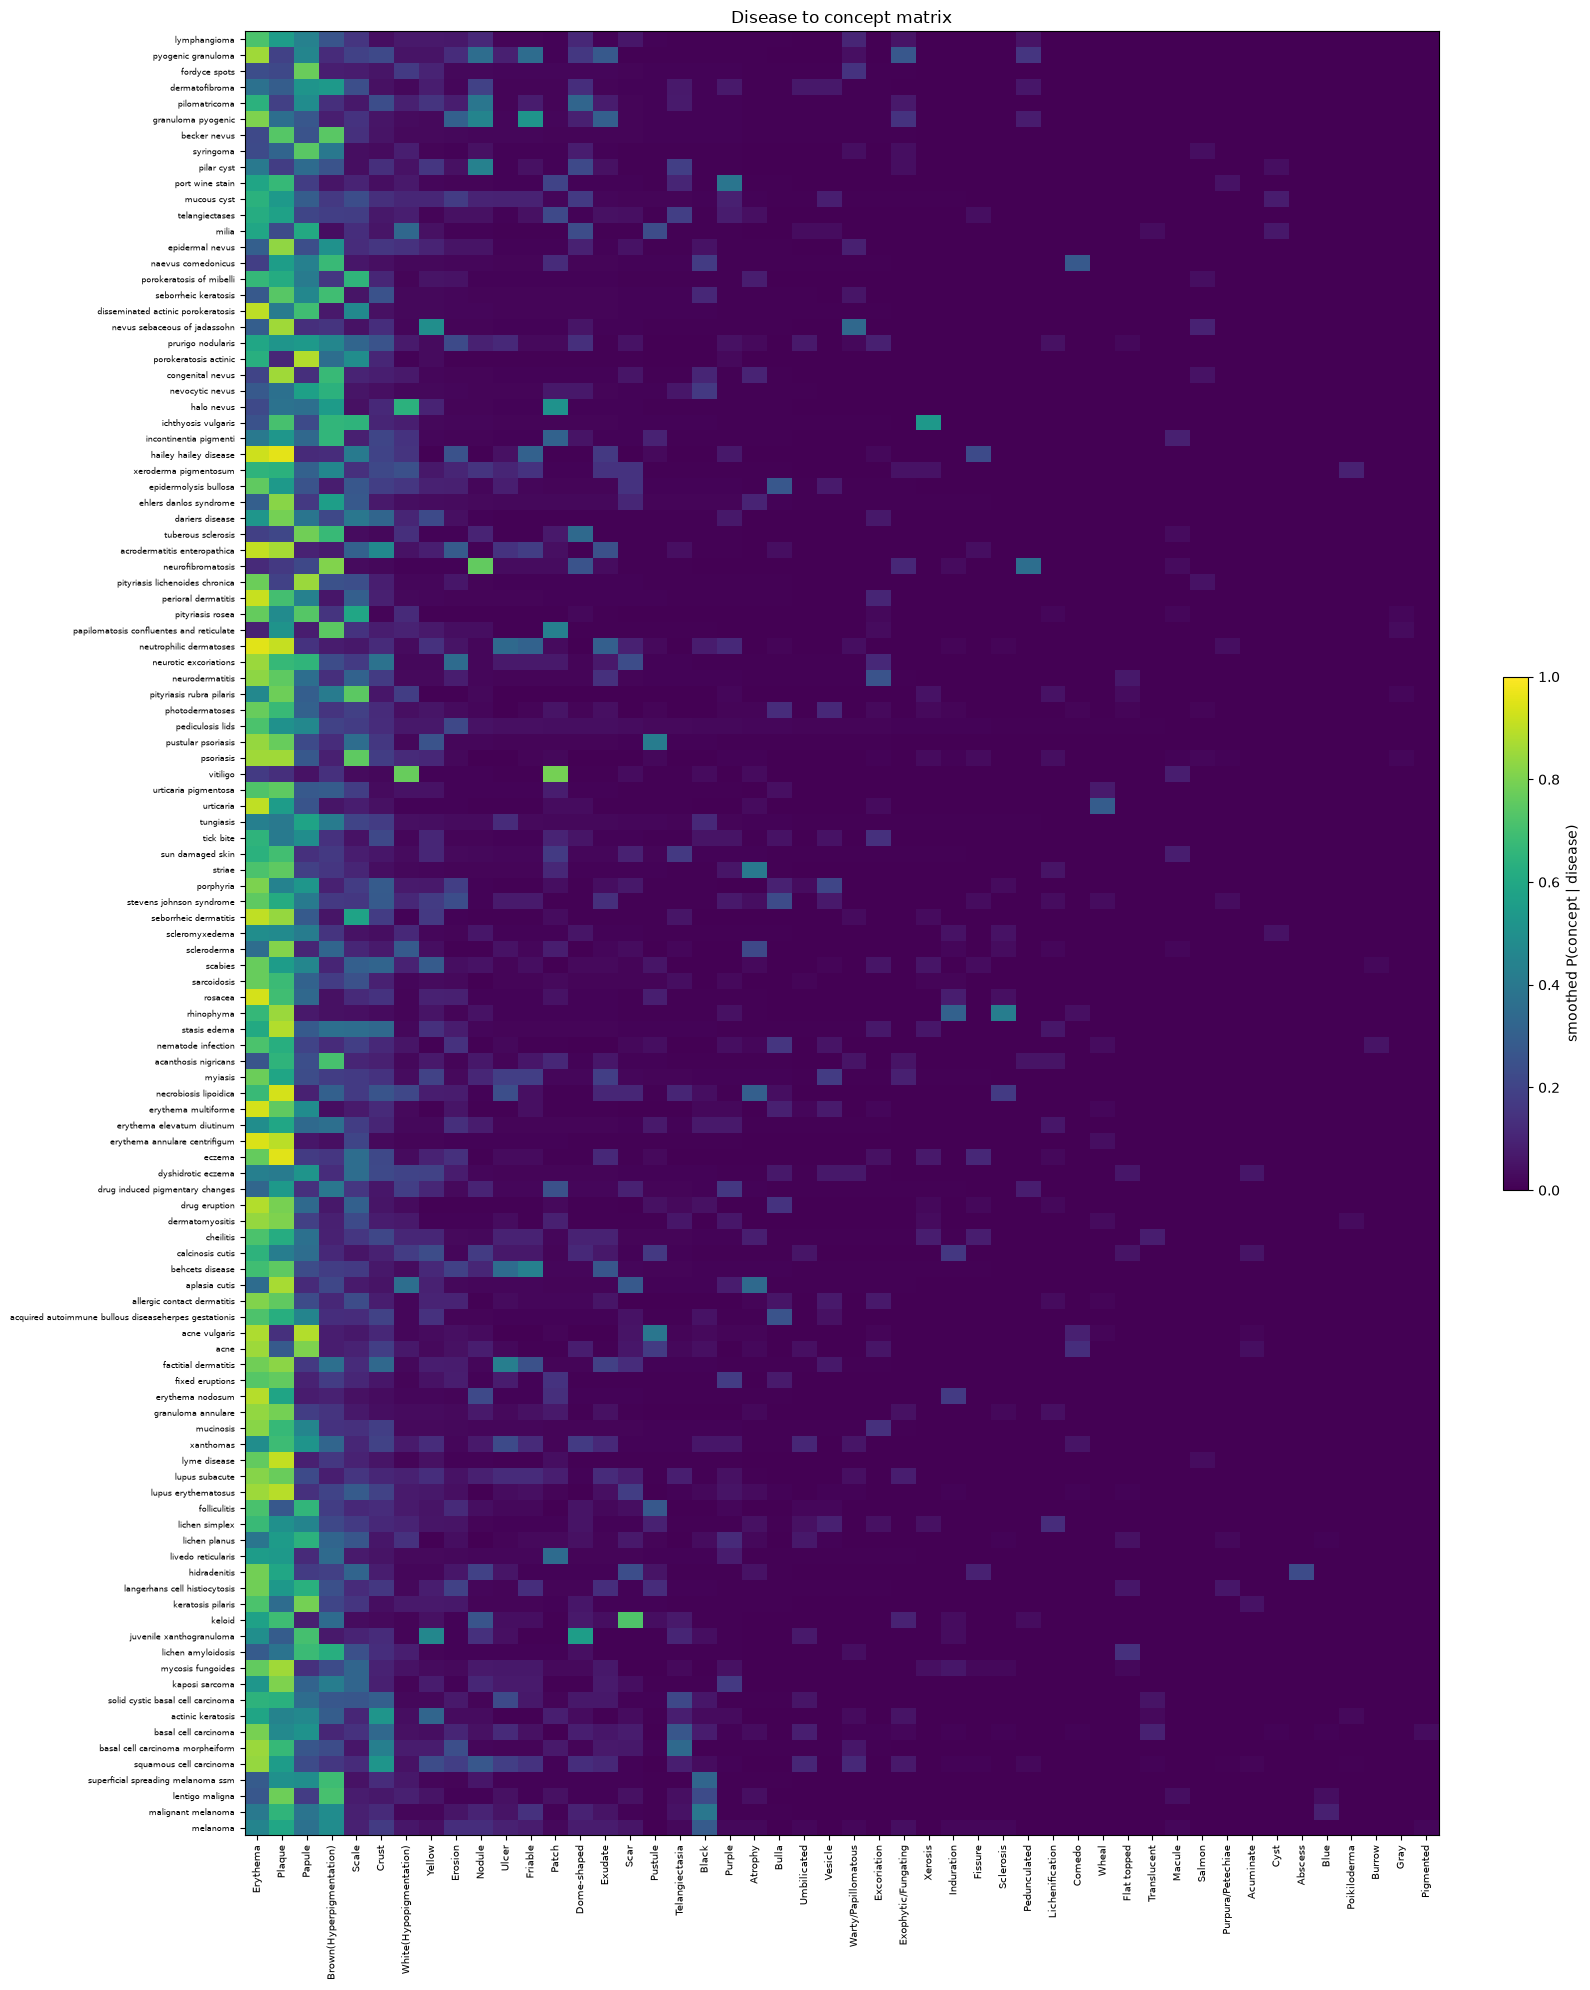

In [9]:
# disease x concept heatmap, diseases sorted by category, concepts by frequency
order_d = df.groupby("label")["nine_partition_label"].first().sort_values().index
order_c = p_c.sort_values(ascending=False).index
M = p_smooth.loc[order_d, order_c]

fig, ax = plt.subplots(figsize=(16, 20))
im = ax.imshow(M.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(order_c))); ax.set_xticklabels(order_c, rotation=90, fontsize=7)
ax.set_yticks(range(len(order_d))); ax.set_yticklabels(order_d, fontsize=6)
plt.colorbar(im, ax=ax, fraction=0.02, label="smoothed P(concept | disease)")
ax.set_title("Disease to concept matrix")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "disease_concept_heatmap.png"), dpi=200); plt.show()

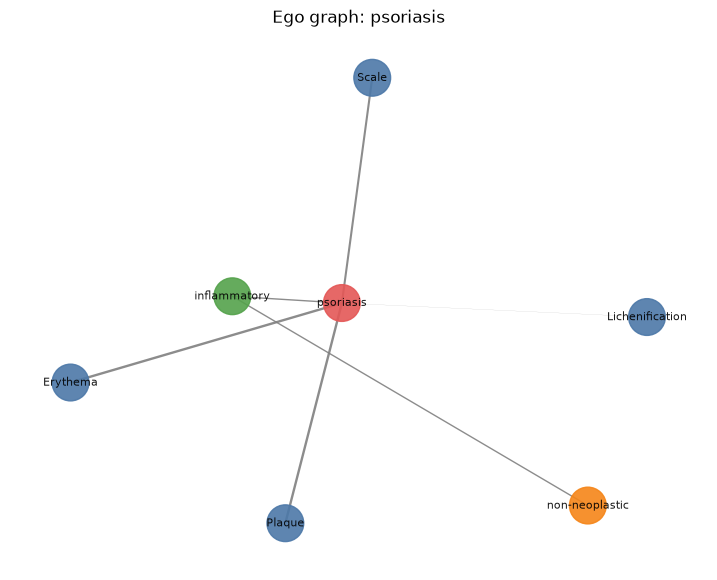

In [10]:
def plot_ego(d):
    nodes = {f"D:{d}"} | set(G.successors(f"D:{d}"))
    cats = [v for v in G.successors(f"D:{d}") if v.startswith("G:")]
    nodes |= {s for c in cats for s in G.successors(c)}
    H = nx.DiGraph(G.subgraph(nodes))
    color = {"disease": "#e45756", "concept": "#4c78a8", "category": "#54a24b", "super_category": "#f58518"}
    pos = nx.spring_layout(H, seed=0, k=1.2)
    plt.figure(figsize=(9, 7))
    nx.draw_networkx(H, pos, labels={n: G.nodes[n]["name"] for n in H}, font_size=8,
                     node_color=[color[G.nodes[n]["ntype"]] for n in H], node_size=700, alpha=0.9,
                     width=[2 * H.edges[e].get("weight", 1) if H.edges[e]["etype"] == "has_concept" else 1 for e in H.edges],
                     edge_color="gray", arrows=False)
    plt.title(f"Ego graph: {d}"); plt.axis("off"); plt.show()

plot_ego("psoriasis")

## 7. Optional: knowledge-driven edges from an LLM

Gives each disease a concept profile from medical knowledge, independent of the images. This is what lets unseen classes have meaningful prototypes in zero-shot. Works with any OpenAI-compatible API (e.g. DeepSeek, Qwen). Set `USE_LLM = True` and fill in the key.

In [11]:
USE_LLM = False
API_BASE = "https://api.deepseek.com"   # any OpenAI-compatible endpoint
API_KEY = os.environ.get("LLM_API_KEY", "")
MODEL = "deepseek-chat"

PROMPT = """You are a board-certified dermatologist. For the skin disease "{disease}",
select the morphological descriptors that are TYPICAL of its clinical presentation,
choosing ONLY from this list:
{concepts}

Return JSON only, in the form {{"concepts": {{"<descriptor>": <confidence 0-1>, ...}}}}.
Include only descriptors with confidence >= 0.5."""

def query_llm(disease):
    from openai import OpenAI
    client = OpenAI(api_key=API_KEY, base_url=API_BASE)
    r = client.chat.completions.create(
        model=MODEL, temperature=0,
        messages=[{"role": "user", "content": PROMPT.format(disease=disease, concepts=", ".join(CONCEPTS))}],
        response_format={"type": "json_object"})
    out = json.loads(r.choices[0].message.content)["concepts"]
    return {k: float(v) for k, v in out.items() if k in CONCEPTS}  # drop anything outside the vocabulary

kb_path = os.path.join(OUT_DIR, "llm_disease_concepts.json")
if USE_LLM:
    kb = json.load(open(kb_path)) if os.path.exists(kb_path) else {}
    for d in DISEASES:
        if d not in kb:
            kb[d] = query_llm(d)
            json.dump(kb, open(kb_path, "w"), indent=1)  # cache after each call
    for d, cs in kb.items():
        for c, conf in cs.items():
            G.add_edge(f"D:{d}", f"C:{c}", etype="has_concept_kb", weight=conf, source="llm")

    # agreement between data-driven and knowledge-driven edges
    rows = []
    for d in DISEASES:
        a, b = sig[d], set(kb.get(d, {}))
        rows.append((d, len(a), len(b), len(a & b) / max(len(a | b), 1)))
    agree = pd.DataFrame(rows, columns=["disease", "n_data", "n_llm", "jaccard"]).sort_values("jaccard")
    print("Mean Jaccard(data, LLM):", agree["jaccard"].mean().round(3))
    display(agree.head(10))

## 8. Export

In [12]:
# node / edge tables
nodes = pd.DataFrame([{"id": n, **d} for n, d in G.nodes(data=True)])
edges = pd.DataFrame([{"src": u, "dst": v, **d} for u, v, d in G.edges(data=True)])
nodes.to_csv(os.path.join(OUT_DIR, "nodes.csv"), index=False)
edges.to_csv(os.path.join(OUT_DIR, "edges.csv"), index=False)
nx.write_graphml(nx.DiGraph(G), os.path.join(OUT_DIR, "skincon_kg.graphml"))  # for Gephi / Cytoscape

# GNN-ready arrays (PyG style): integer ids, edge_index, edge_type, edge_weight
node_ids = {n: i for i, n in enumerate(nodes["id"])}
etypes = sorted(edges["etype"].unique())
np.savez(os.path.join(OUT_DIR, "kg_arrays.npz"),
         node_names=np.array(nodes["id"].tolist(), dtype=str),
         node_type=nodes["ntype"].map({t: i for i, t in enumerate(sorted(nodes["ntype"].unique()))}).values,
         edge_index=np.stack([edges["src"].map(node_ids).values, edges["dst"].map(node_ids).values]),
         edge_type=edges["etype"].map({t: i for i, t in enumerate(etypes)}).values,
         edge_weight=edges["weight"].values.astype(np.float32),
         etype_names=np.array(etypes))
print("Saved to", OUT_DIR, "->", sorted(os.listdir(OUT_DIR)))

Saved to data/skincon_kg -> ['disease_concept_heatmap.png', 'disease_concept_prob.csv', 'edges.csv', 'kg_arrays.npz', 'nodes.csv', 'skincon_kg.graphml']
